# Modul Machine Learning: Prediksi Gagal Bayar PayLater
Notebook ini mengajarkan alur machine learning **tahap demi tahap** memakai data PayLater.

**Tujuan:** memprediksi apakah pengguna PayLater akan **gagal bayar** (`gagal_bayar = 1`) atau **lancar** (`0`).

| Tahap | Isi |
|---|---|
| 1 | Membuat & memahami dataset |
| 2 | Eksplorasi data (EDA) |
| 3 | Preprocessing |
| 4 | Baseline: Logistic Regression |
| 5 | Evaluasi model |
| 6 | Decision Tree |
| 7 | Random Forest |
| 8 | Gradient Boosting |
| 9 | Cross-validation & tuning |
| 10 | Threshold & simpan model |

## Tahap 0 - Persiapan library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay, precision_recall_curve)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## Tahap 1 - Membuat dan memahami dataset
Kita membuat **dataset simulasi (sintetis)** agar modul bisa dijalankan siapa saja dan aman diunggah ke GitHub (tidak berisi data pribadi).
Jika nanti punya data asli, cukup ganti `df = pd.read_csv("data/paylater.csv")` dan sesuaikan nama kolom.

In [ ]:
def buat_dataset(n=5000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    df = pd.DataFrame({
        "customer_id": [f"C{i:05d}" for i in range(1, n + 1)],
        "usia": rng.integers(18, 61, n),
        "jenis_kelamin": rng.choice(["L", "P"], n),
        "pendidikan": rng.choice(["SMA", "D3", "S1", "S2"], n, p=[0.35, 0.15, 0.42, 0.08]),
        "status_pekerjaan": rng.choice(["Karyawan", "Wiraswasta", "Pelajar", "Lainnya"], n, p=[0.5, 0.25, 0.15, 0.10]),
    })
    df["penghasilan_bulanan"] = (rng.lognormal(mean=15.6, sigma=0.5, size=n)).round(-3)
    df["lama_pengguna_bulan"] = rng.integers(1, 61, n)
    df["jumlah_transaksi_3bln"] = rng.poisson(8, n)
    df["rata_transaksi"] = rng.lognormal(12.0, 0.6, n).round(-2)
    df["limit_paylater"] = (df["penghasilan_bulanan"] * rng.uniform(0.2, 0.8, n)).round(-5)
    df["rasio_penggunaan_limit"] = np.clip(rng.beta(2, 3, n), 0, 1).round(3)
    df["jumlah_telat_6bln"] = rng.poisson(0.8, n)
    df["cicilan_aktif"] = rng.integers(0, 6, n)
    df["rasio_cicilan_penghasilan"] = np.clip(
        df["cicilan_aktif"] * rng.uniform(0.03, 0.12, n), 0, 1).round(3)

    # Skor risiko (aturan tersembunyi) -> probabilitas gagal bayar
    z = (-4.6
         + 3.0 * df["rasio_penggunaan_limit"]
         + 0.8 * df["jumlah_telat_6bln"]
         + 3.0 * df["rasio_cicilan_penghasilan"]
         - 0.012 * df["lama_pengguna_bulan"]
         - 0.015 * (df["usia"] - 18)
         + 0.5 * (df["status_pekerjaan"] == "Pelajar")
         - 0.3 * (df["penghasilan_bulanan"] / 1e7)
         + rng.normal(0, 0.25, n))
    p = 1 / (1 + np.exp(-z))
    df["gagal_bayar"] = (rng.uniform(size=n) < p).astype(int)

    # Sisipkan missing value agar latihan preprocessing realistis
    df.loc[rng.choice(n, int(0.05 * n), replace=False), "penghasilan_bulanan"] = np.nan
    df.loc[rng.choice(n, int(0.03 * n), replace=False), "pendidikan"] = np.nan
    return df

df = buat_dataset()


,customer_id,usia,jenis_kelamin,pendidikan,status_pekerjaan,penghasilan_bulanan,lama_pengguna_bulan,jumlah_transaksi_3bln,rata_transaksi,limit_paylater,rasio_penggunaan_limit,jumlah_telat_6bln,cicilan_aktif,rasio_cicilan_penghasilan,gagal_bayar
0,C00001,21,L,SMA,Wiraswasta,12167000.0,60,3,204200.0,9000000.0,0.155,2,1,0.096,0
1,C00002,51,L,S1,Wiraswasta,14391000.0,52,3,249200.0,8900000.0,0.264,1,1,0.118,0
2,C00003,46,P,S1,Karyawan,7027000.0,29,8,55700.0,5100000.0,0.511,0,5,0.160,0
3,C00004,36,P,SMA,Karyawan,3224000.0,21,12,91200.0,1000000.0,0.495,0,3,0.251,0
4,C00005,36,P,SMA,Karyawan,14451000.0,29,11,196100.0,8700000.0,0.616,1,5,0.182,0


In [ ]:
df.to_csv("../data/paylater.csv", index=False)
df.head()

NameError: name 'df' is not defined

In [3]:
print("Ukuran data :", df.shape)
df.info()

Ukuran data : (5000, 15)
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                5000 non-null   str    
 1   usia                       5000 non-null   int64  
 2   jenis_kelamin              5000 non-null   str    
 3   pendidikan                 4850 non-null   str    
 4   status_pekerjaan           5000 non-null   str    
 5   penghasilan_bulanan        4750 non-null   float64
 6   lama_pengguna_bulan        5000 non-null   int64  
 7   jumlah_transaksi_3bln      5000 non-null   int64  
 8   rata_transaksi             5000 non-null   float64
 9   limit_paylater             5000 non-null   float64
 10  rasio_penggunaan_limit     5000 non-null   float64
 11  jumlah_telat_6bln          5000 non-null   int64  
 12  cicilan_aktif              5000 non-null   int64  
 13  rasio_cicilan_penghasilan  5000 no

**Kamus data singkat**
- `usia`, `jenis_kelamin`, `pendidikan`, `status_pekerjaan`: profil nasabah
- `penghasilan_bulanan`: penghasilan per bulan (Rp)
- `lama_pengguna_bulan`: sudah berapa bulan memakai PayLater
- `rasio_penggunaan_limit`: porsi limit yang terpakai (0-1)
- `jumlah_telat_6bln`: berapa kali telat bayar dalam 6 bulan terakhir
- `rasio_cicilan_penghasilan`: beban cicilan dibanding penghasilan
- **`gagal_bayar`: target (1 = gagal bayar, 0 = lancar)**

## Tahap 2 - Eksplorasi Data (EDA)

In [4]:
print("Missing value per kolom:")
print(df.isna().sum()[df.isna().sum() > 0])
print()
print("Distribusi target:")
print(df["gagal_bayar"].value_counts())
print(df["gagal_bayar"].value_counts(normalize=True).round(3))

Missing value per kolom:
pendidikan             150
penghasilan_bulanan    250
dtype: int64

Distribusi target:
gagal_bayar
0    4611
1     389
Name: count, dtype: int64
gagal_bayar
0    0.922
1    0.078
Name: proportion, dtype: float64


In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
usia,5000.0,38.94,12.44,18.00,28.00,39.00,50.00,60.00
penghasilan_bulanan,4750.0,6868253.89,3590900.39,937000.00,4292000.00,6048500.00,8551500.00,29507000.00
lama_pengguna_bulan,5000.0,30.99,17.48,1.00,16.00,31.00,47.00,60.00
jumlah_transaksi_3bln,5000.0,8.02,2.88,0.00,6.00,8.00,10.00,21.00
rata_transaksi,5000.0,196437.76,132316.70,23600.00,109375.00,161500.00,245400.00,1680300.00
limit_paylater,5000.0,3461040.00,2276566.42,300000.00,1900000.00,2900000.00,4400000.00,20500000.00
rasio_penggunaan_limit,5000.0,0.40,0.20,0.01,0.25,0.39,0.55,0.95
jumlah_telat_6bln,5000.0,0.81,0.91,0.00,0.00,1.00,1.00,6.00
cicilan_aktif,5000.0,2.49,1.70,0.00,1.00,2.00,4.00,5.00
rasio_cicilan_penghasilan,5000.0,0.19,0.15,0.00,0.07,0.16,0.28,0.60


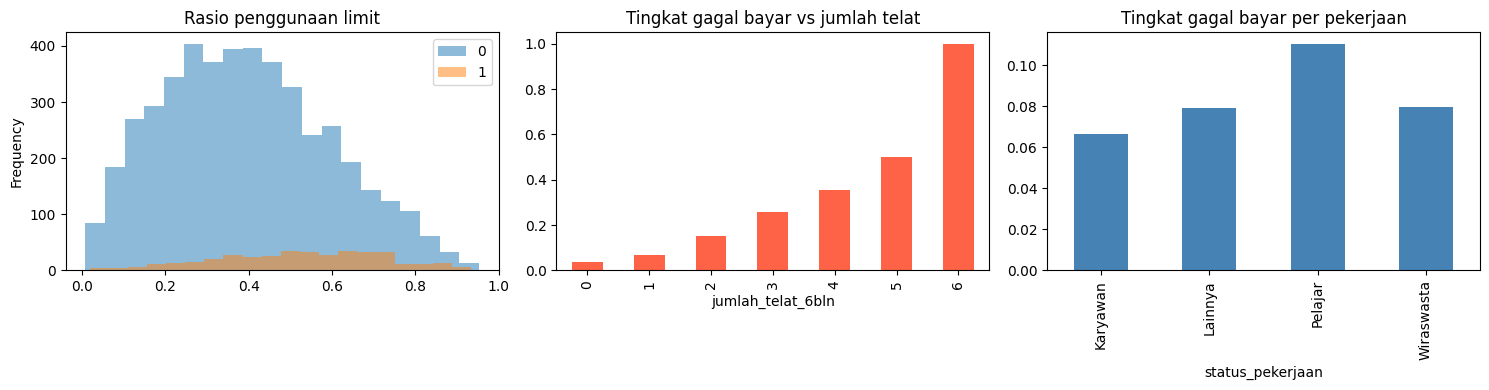

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.groupby("gagal_bayar")["rasio_penggunaan_limit"].plot(kind="hist", alpha=0.5, bins=20, ax=ax[0], legend=True)
ax[0].set_title("Rasio penggunaan limit")
df.groupby("jumlah_telat_6bln")["gagal_bayar"].mean().plot(kind="bar", ax=ax[1], color="tomato")
ax[1].set_title("Tingkat gagal bayar vs jumlah telat")
df.groupby("status_pekerjaan")["gagal_bayar"].mean().plot(kind="bar", ax=ax[2], color="steelblue")
ax[2].set_title("Tingkat gagal bayar per pekerjaan")
plt.tight_layout(); plt.show()

**Latihan kecil:** Apa hubungan `jumlah_telat_6bln` dengan gagal bayar? Apakah target seimbang (balanced)?
Catatan: data gagal bayar biasanya **tidak seimbang** (kelas 1 jauh lebih sedikit), sehingga *accuracy saja menyesatkan*.

## Tahap 3 - Preprocessing
Langkah: pilih fitur -> bagi data train/test -> tangani missing value -> encode kategori -> scaling.
Semuanya dibungkus dalam **Pipeline** agar tidak terjadi *data leakage*.

In [7]:
target = "gagal_bayar"
X = df.drop(columns=[target, "customer_id"])   # customer_id bukan fitur
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Rasio gagal bayar train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Train: (4000, 13)  Test: (1000, 13)
Rasio gagal bayar train: 0.078 | test: 0.078


In [8]:
fitur_num = X.select_dtypes(include="number").columns.tolist()
fitur_kat = X.select_dtypes(exclude="number").columns.tolist()
print("Numerik :", fitur_num)
print("Kategori:", fitur_kat)

prep_linear = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), fitur_num),
    ("kat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore"))]), fitur_kat),
])

# Model berbasis pohon tidak butuh scaling
prep_pohon = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), fitur_num),
    ("kat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore"))]), fitur_kat),
])

Numerik : ['usia', 'penghasilan_bulanan', 'lama_pengguna_bulan', 'jumlah_transaksi_3bln', 'rata_transaksi', 'limit_paylater', 'rasio_penggunaan_limit', 'jumlah_telat_6bln', 'cicilan_aktif', 'rasio_cicilan_penghasilan']
Kategori: ['jenis_kelamin', 'pendidikan', 'status_pekerjaan']


## Tahap 4 - Baseline: Logistic Regression
Selalu mulai dari model **sederhana** sebagai pembanding (baseline). Logistic Regression cepat dan mudah dijelaskan.

In [9]:
model_lr = Pipeline([("prep", prep_linear),
                     ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
model_lr.fit(X_train, y_train)

pred_lr = model_lr.predict(X_test)
proba_lr = model_lr.predict_proba(X_test)[:, 1]
print("Accuracy:", round(accuracy_score(y_test, pred_lr), 3))
print("ROC-AUC :", round(roc_auc_score(y_test, proba_lr), 3))

Accuracy: 0.927
ROC-AUC : 0.809


## Tahap 5 - Evaluasi model dengan benar
Untuk kasus gagal bayar:
- **Precision**: dari yang diprediksi gagal bayar, berapa yang benar?
- **Recall**: dari semua yang benar-benar gagal bayar, berapa yang tertangkap? (penting agar risiko tidak lolos)
- **F1**: rata-rata harmonik precision & recall
- **ROC-AUC**: kemampuan model membedakan dua kelas (tidak bergantung threshold)

In [10]:
def evaluasi(nama, model, X_te, y_te, threshold=0.5):
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"model": nama,
            "accuracy": accuracy_score(y_te, pred),
            "precision": precision_score(y_te, pred, zero_division=0),
            "recall": recall_score(y_te, pred),
            "f1": f1_score(y_te, pred),
            "roc_auc": roc_auc_score(y_te, proba)}

hasil = [evaluasi("Logistic Regression", model_lr, X_test, y_test)]
pd.DataFrame(hasil).round(3)

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.927,0.778,0.09,0.161,0.809


              precision    recall  f1-score   support

      Lancar       0.93      1.00      0.96       922
 Gagal bayar       0.78      0.09      0.16        78

    accuracy                           0.93      1000
   macro avg       0.85      0.54      0.56      1000
weighted avg       0.92      0.93      0.90      1000



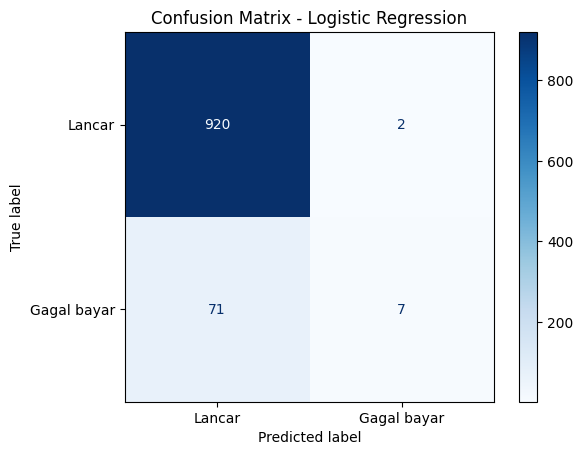

In [11]:
print(classification_report(y_test, pred_lr, target_names=["Lancar", "Gagal bayar"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, pred_lr, display_labels=["Lancar", "Gagal bayar"], cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression"); plt.show()

**Cara membaca confusion matrix:** baris = kenyataan, kolom = prediksi.
Sel kiri-bawah (*False Negative*) adalah nasabah gagal bayar yang **lolos** - ini yang paling mahal bagi perusahaan.

## Tahap 6 - Decision Tree
Model berupa serangkaian aturan "jika-maka". Mudah divisualisasikan tetapi cenderung **overfitting** jika terlalu dalam.

In [12]:
for depth in [2, 4, 6, 10, None]:
    m = Pipeline([("prep", prep_pohon),
                  ("clf", DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE))])
    m.fit(X_train, y_train)
    auc_tr = roc_auc_score(y_train, m.predict_proba(X_train)[:, 1])
    auc_te = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
    print(f"max_depth={str(depth):>4} | AUC train={auc_tr:.3f} | AUC test={auc_te:.3f}")

max_depth=   2 | AUC train=0.726 | AUC test=0.744


max_depth=   4 | AUC train=0.786 | AUC test=0.775


max_depth=   6 | AUC train=0.848 | AUC test=0.722
max_depth=  10 | AUC train=0.962 | AUC test=0.640


max_depth=None | AUC train=1.000 | AUC test=0.591


Perhatikan: pada `max_depth=None`, AUC train mendekati 1 tetapi AUC test turun. Itulah **overfitting**.

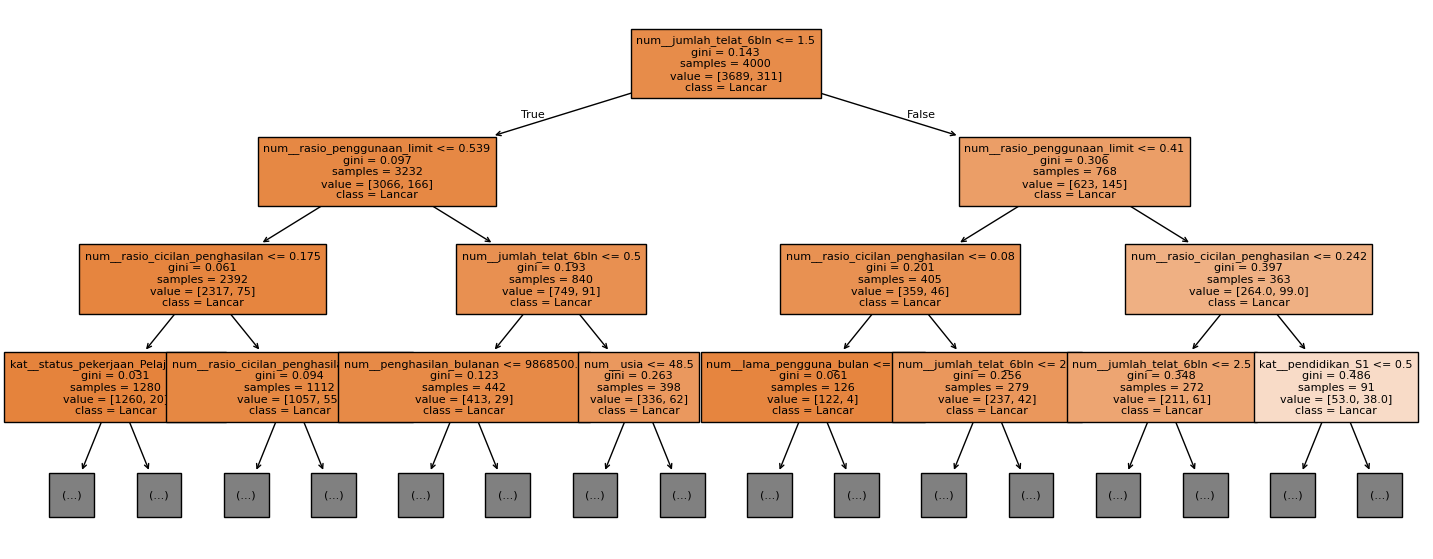

In [13]:
model_dt = Pipeline([("prep", prep_pohon),
                     ("clf", DecisionTreeClassifier(max_depth=4, min_samples_leaf=30, random_state=RANDOM_STATE))])
model_dt.fit(X_train, y_train)
hasil.append(evaluasi("Decision Tree", model_dt, X_test, y_test))

nama_fitur = model_dt.named_steps["prep"].get_feature_names_out()
plt.figure(figsize=(18, 7))
plot_tree(model_dt.named_steps["clf"], max_depth=3, feature_names=nama_fitur,
          class_names=["Lancar", "Gagal"], filled=True, fontsize=8)
plt.show()

## Tahap 7 - Random Forest
Gabungan **banyak pohon** yang dilatih pada sampel acak; hasilnya di-voting. Lebih stabil dan umumnya lebih akurat dari satu pohon.

In [14]:
model_rf = Pipeline([("prep", prep_pohon),
                     ("clf", RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10,
                                                    class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))])
model_rf.fit(X_train, y_train)
hasil.append(evaluasi("Random Forest", model_rf, X_test, y_test))
pd.DataFrame(hasil).round(3)

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.927,0.778,0.090,0.161,0.809
1,Decision Tree,0.917,0.333,0.064,0.108,0.779
2,Random Forest,0.852,0.257,0.474,0.333,0.786


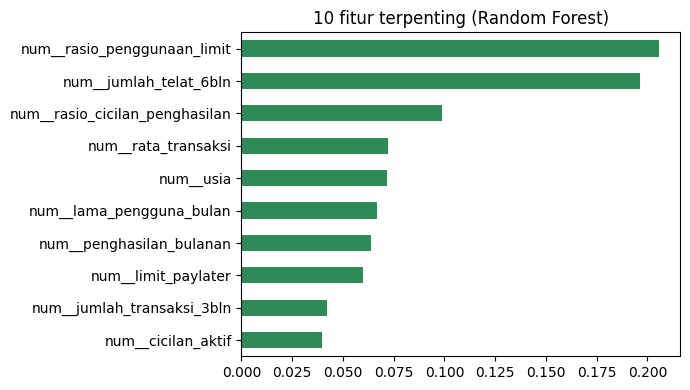

In [15]:
# Fitur apa yang paling berpengaruh?
imp = pd.Series(model_rf.named_steps["clf"].feature_importances_,
                index=model_rf.named_steps["prep"].get_feature_names_out()).sort_values()
imp.tail(10).plot(kind="barh", figsize=(7, 4), color="seagreen")
plt.title("10 fitur terpenting (Random Forest)"); plt.tight_layout(); plt.show()

## Tahap 8 - Gradient Boosting
Pohon dibangun **berurutan**; setiap pohon baru memperbaiki kesalahan pohon sebelumnya. Sering menjadi model terbaik untuk data tabular.
Kita pakai `HistGradientBoostingClassifier` (bawaan scikit-learn, cepat).

In [16]:
model_gb = Pipeline([("prep", prep_pohon),
                     ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_depth=4,
                                                            class_weight="balanced", random_state=RANDOM_STATE))])
model_gb.fit(X_train, y_train)
hasil.append(evaluasi("Gradient Boosting", model_gb, X_test, y_test))
tabel = pd.DataFrame(hasil).set_index("model").round(3)
tabel

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.927,0.778,0.090,0.161,0.809
Decision Tree,0.917,0.333,0.064,0.108,0.779
Random Forest,0.852,0.257,0.474,0.333,0.786
Gradient Boosting,0.817,0.203,0.462,0.282,0.751


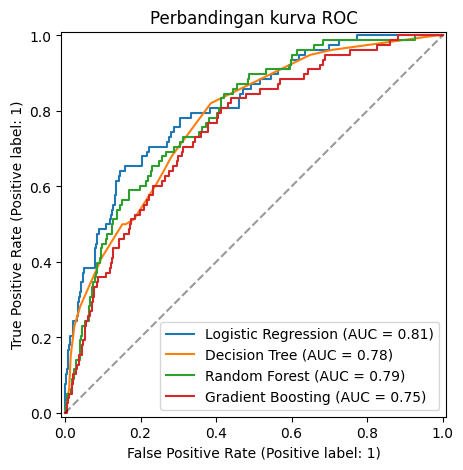

In [17]:
fig, ax = plt.subplots(figsize=(6, 5))
for nama, m in [("Logistic Regression", model_lr), ("Decision Tree", model_dt),
                ("Random Forest", model_rf), ("Gradient Boosting", model_gb)]:
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=nama, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.title("Perbandingan kurva ROC"); plt.show()

## Tahap 9 - Cross-validation & tuning
Satu kali split bisa kebetulan bagus/jelek. **Cross-validation** menguji model pada beberapa pembagian data.

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for nama, m in [("Logistic Regression", model_lr), ("Random Forest", model_rf), ("Gradient Boosting", model_gb)]:
    skor = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{nama:<22} AUC = {skor.mean():.3f} (+/- {skor.std():.3f})")

Logistic Regression    AUC = 0.781 (+/- 0.019)


Random Forest          AUC = 0.761 (+/- 0.021)


Gradient Boosting      AUC = 0.724 (+/- 0.013)


In [19]:
# Tuning hyperparameter dengan RandomizedSearchCV
param = {
    "clf__learning_rate": [0.02, 0.05, 0.1],
    "clf__max_depth": [2, 3, 4, 6],
    "clf__max_iter": [100, 200, 300],
    "clf__min_samples_leaf": [20, 40, 80],
}
search = RandomizedSearchCV(model_gb, param, n_iter=12, scoring="roc_auc", cv=cv,
                            random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)
print("Parameter terbaik:", search.best_params_)
print("AUC CV terbaik   :", round(search.best_score_, 3))

model_final = search.best_estimator_
hasil.append(evaluasi("Gradient Boosting (tuned)", model_final, X_test, y_test))
pd.DataFrame(hasil).set_index("model").round(3)

Parameter terbaik: {'clf__min_samples_leaf': 40, 'clf__max_iter': 200, 'clf__max_depth': 2, 'clf__learning_rate': 0.02}
AUC CV terbaik   : 0.774


,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.927,0.778,0.090,0.161,0.809
Decision Tree,0.917,0.333,0.064,0.108,0.779
Random Forest,0.852,0.257,0.474,0.333,0.786
Gradient Boosting,0.817,0.203,0.462,0.282,0.751
Gradient Boosting (tuned),0.724,0.183,0.731,0.292,0.801


## Tahap 10 - Mengatur threshold & menyimpan model
Threshold bawaan 0.5 belum tentu terbaik. Jika perusahaan lebih takut **kehilangan** nasabah berisiko (recall tinggi), turunkan threshold.

In [20]:
proba = model_final.predict_proba(X_test)[:, 1]
for th in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba >= th).astype(int)
    print(f"threshold={th:.1f} | precision={precision_score(y_test, pred, zero_division=0):.3f} "
          f"| recall={recall_score(y_test, pred):.3f} | f1={f1_score(y_test, pred):.3f}")

threshold=0.2 | precision=0.088 | recall=0.987 | f1=0.162
threshold=0.3 | precision=0.110 | recall=0.962 | f1=0.198
threshold=0.4 | precision=0.142 | recall=0.846 | f1=0.243
threshold=0.5 | precision=0.183 | recall=0.731 | f1=0.292
threshold=0.6 | precision=0.220 | recall=0.564 | f1=0.317
threshold=0.7 | precision=0.281 | recall=0.346 | f1=0.310


In [21]:
THRESHOLD = 0.4   # pilih sesuai kebijakan bisnis
joblib.dump({"model": model_final, "threshold": THRESHOLD}, "../models/model_paylater.joblib")
print("Model tersimpan di ../models/model_paylater.joblib")

Model tersimpan di ../models/model_paylater.joblib


In [22]:
# Contoh prediksi nasabah baru
paket = joblib.load("../models/model_paylater.joblib")
baru = pd.DataFrame([{
    "usia": 24, "jenis_kelamin": "P", "pendidikan": "S1", "status_pekerjaan": "Karyawan",
    "penghasilan_bulanan": 6_000_000, "lama_pengguna_bulan": 6, "jumlah_transaksi_3bln": 10,
    "rata_transaksi": 250_000, "limit_paylater": 2_000_000, "rasio_penggunaan_limit": 0.9,
    "jumlah_telat_6bln": 3, "cicilan_aktif": 4, "rasio_cicilan_penghasilan": 0.35}])
p = paket["model"].predict_proba(baru)[0, 1]
print(f"Probabilitas gagal bayar: {p:.1%}")
print("Keputusan:", "RISIKO TINGGI" if p >= paket["threshold"] else "RISIKO RENDAH")

Probabilitas gagal bayar: 84.3%
Keputusan: RISIKO TINGGI


## Kesimpulan & tugas mandiri
1. Alur ML: data -> EDA -> preprocessing -> baseline -> model lebih kompleks -> evaluasi -> tuning -> simpan.
2. Jangan hanya melihat accuracy pada data tidak seimbang; gunakan precision, recall, F1, ROC-AUC.
3. Bungkus preprocessing dalam Pipeline untuk mencegah data leakage.

**Tugas:**
- Ubah `buat_dataset(n=...)` menjadi 20.000 baris. Apakah ranking model berubah?
- Tambahkan fitur baru (mis. `rasio_transaksi_per_limit`) dan lihat dampaknya pada AUC.
- Coba `class_weight` pada Logistic Regression; bandingkan recall.
- Tulis laporan 1 halaman: model mana yang direkomendasikan dan mengapa.